In [1]:
import pandas as pd

file_path = "../data/cleaned_logistics_data.csv"

df = pd.read_csv(file_path, encoding="latin1")

print("Cleaned dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Cleaned dataset loaded successfully.
Shape: (180519, 47)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Calculated Shipping Days,Shipping Delay
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,3,-1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,5,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,4,0
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,3,-1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,2,-2


In [2]:
df.shape

(180519, 47)

In [3]:
df.columns.tolist()

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Id',
 'Customer Segment',
 'Customer State',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'Order Customer Id',
 'order date (DateOrders)',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Product Card Id',
 'Product Category Id',
 'Product Image',
 'Product Name',
 'Product Price',
 'Product Status',
 'shipping date (DateOrders)',
 'Shipping Mode',
 'Calculated Shipping Days',
 'Shipping Delay']

In [4]:
df.isnull().sum()

Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Id                      0
Category Name                    0
Customer City                    0
Customer Country                 0
Customer Id                      0
Customer Segment                 0
Customer State                   0
Department Id                    0
Department Name                  0
Latitude                         0
Longitude                        0
Market                           0
Order City                       0
Order Country                    0
Order Customer Id                0
order date (DateOrders)          0
Order Id                         0
Order Item Cardprod Id           0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Id                    0
Order Item Product P

In [5]:
df["Delivery Status"].value_counts()

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

In [6]:
df.dtypes

Type                                 str
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                      str
Late_delivery_risk                 int64
Category Id                        int64
Category Name                        str
Customer City                        str
Customer Country                     str
Customer Id                        int64
Customer Segment                     str
Customer State                       str
Department Id                      int64
Department Name                      str
Latitude                         float64
Longitude                        float64
Market                               str
Order City                           str
Order Country                        str
Order Customer Id                  int64
order date (DateOrders)              str
Order Id                           int64
Order Item Cardp

In [7]:
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"]
)

df["shipping date (DateOrders)"] = pd.to_datetime(
    df["shipping date (DateOrders)"]
)

df[["order date (DateOrders)", "shipping date (DateOrders)"]].head()

,order date (DateOrders),shipping date (DateOrders)
0,2018-01-31 22:56:00,2018-02-03 22:56:00
1,2018-01-13 12:27:00,2018-01-18 12:27:00
2,2018-01-13 12:06:00,2018-01-17 12:06:00
3,2018-01-13 11:45:00,2018-01-16 11:45:00
4,2018-01-13 11:24:00,2018-01-15 11:24:00


In [8]:
date_difference = (
    df["shipping date (DateOrders)"] -
    df["order date (DateOrders)"]
).dt.days

mismatches = (
    date_difference != df["Days for shipping (real)"]
).sum()

print("Number of records where date difference differs from the official shipping duration:", mismatches)

df[[
    "Days for shipping (real)",
    "Days for shipment (scheduled)"
]].head()

Number of records where date difference differs from the official shipping duration: 4657


,Days for shipping (real),Days for shipment (scheduled)
0,3,4
1,5,4
2,4,4
3,3,4
4,2,4


In [9]:
import pandas as pd

file_path = "../data/DataCoSupplyChainDataset.csv"

df = pd.read_csv(file_path, encoding="latin1")

df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [10]:
# Validate the dataset's official shipping duration

df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"]
)

df["shipping date (DateOrders)"] = pd.to_datetime(
    df["shipping date (DateOrders)"]
)

date_difference = (
    df["shipping date (DateOrders)"] -
    df["order date (DateOrders)"]
).dt.days

mismatches = (
    date_difference != df["Days for shipping (real)"]
).sum()

print(
    "Number of records where date difference differs from the official shipping duration:",
    mismatches
)

df[[
    "Days for shipping (real)",
    "Days for shipment (scheduled)"
]].head()

Number of records where date difference differs from the official shipping duration: 4657


,Days for shipping (real),Days for shipment (scheduled)
0,3,4
1,5,4
2,4,4
3,3,4
4,2,4


In [11]:
df["Shipping Delay"] = (
    df["Days for shipping (real)"] -
    df["Days for shipment (scheduled)"]
)

df[[
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping Delay",
    "Delivery Status"
]].head(10)

,Days for shipping (real),Days for shipment (scheduled),Shipping Delay,Delivery Status
0,3,4,-1,Advance shipping
1,5,4,1,Late delivery
2,4,4,0,Shipping on time
3,3,4,-1,Advance shipping
4,2,4,-2,Advance shipping
5,6,4,2,Shipping canceled
6,2,1,1,Late delivery
7,2,1,1,Late delivery
8,3,2,1,Late delivery
9,2,1,1,Late delivery


In [12]:
pd.crosstab(
    df["Shipping Delay"],
    df["Delivery Status"]
)

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping Delay,,,,
-2,20873,0,793,0
-1,20719,0,981,0
0,0,0,1557,32196
1,0,57957,2690,0
2,0,27551,1167,0
3,0,6772,280,0
4,0,6697,286,0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Order Status"].value_counts()

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

In [15]:
df["Shipping Mode"].value_counts()

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

In [16]:
df[[
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Product Price"
]].describe()

,Days for shipping (real),Days for shipment (scheduled),Order Item Quantity,Sales,Order Item Total,Product Price
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000
mean,3.497654,2.931847,2.127638,203.772096,183.107609,141.232550
std,1.623722,1.374449,1.453451,132.273077,120.043670,139.732492
min,0.000000,0.000000,1.000000,9.990000,7.490000,9.990000
25%,2.000000,2.000000,1.000000,119.980003,104.379997,50.000000
50%,3.000000,4.000000,1.000000,199.919998,163.990005,59.990002
75%,5.000000,4.000000,3.000000,299.950012,247.399994,199.990005
max,6.000000,4.000000,5.000000,1999.989990,1939.989990,1999.989990


In [17]:
df.columns.tolist()

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Id',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'Order Customer Id',
 'order date (DateOrders)',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Image',
 'Product Name',
 'Product P

In [18]:
df.isnull().sum().sum()

np.int64(336209)

In [19]:

df["Delivery Status"].value_counts()

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

In [20]:
delivery_percentage = (
    df["Delivery Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

delivery_percentage

Delivery Status
Late delivery        54.83
Advance shipping     23.04
Shipping on time     17.84
Shipping canceled     4.30
Name: proportion, dtype: float64

In [21]:
late_delivery_by_mode = (
    df.assign(
        Is_Late=df["Delivery Status"].eq("Late delivery")
    )
    .groupby("Shipping Mode")["Is_Late"]
    .mean()
    .mul(100)
    .round(2)
)

late_delivery_by_mode

Shipping Mode
First Class       95.32
Same Day          45.74
Second Class      76.63
Standard Class    38.07
Name: Is_Late, dtype: float64

In [22]:
shipping_analysis = (
    df.groupby("Shipping Mode")
      .agg(
          Orders=("Order Id", "count"),
          Late_Rate=("Delivery Status", lambda x: (x == "Late delivery").mean() * 100)
      )
      .round(2)
      .sort_values("Late_Rate", ascending=False)
)

shipping_analysis

,Orders,Late_Rate
Shipping Mode,,
First Class,27814,95.32
Second Class,35216,76.63
Same Day,9737,45.74
Standard Class,107752,38.07


<Axes: title={'center': 'Late Delivery Rate by Shipping Mode'}, xlabel='Late Delivery Rate (%)', ylabel='Shipping Mode'>

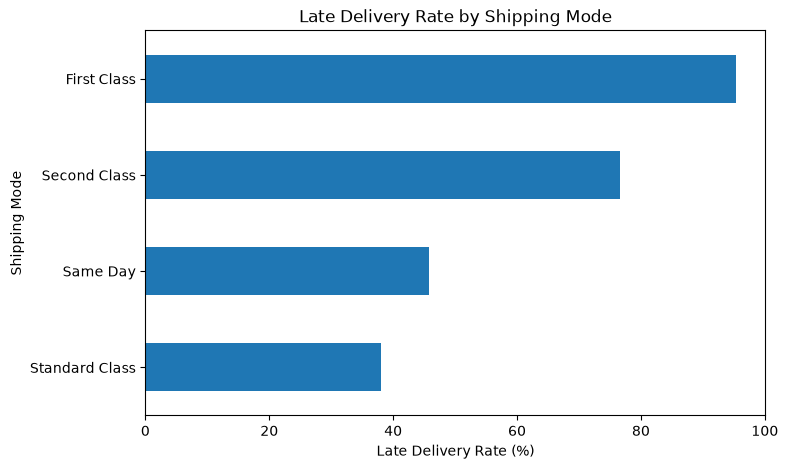

In [23]:
shipping_analysis["Late_Rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="Late Delivery Rate by Shipping Mode",
    xlabel="Late Delivery Rate (%)",
    ylabel="Shipping Mode"
)


In [24]:
shipping_analysis = (
    df.groupby("Shipping Mode")
      .agg(
          Orders=("Order Id", "count"),
          Late_Rate=("Delivery Status", lambda x: (x == "Late delivery").mean() * 100)
      )
      .round(2)
      .sort_values("Late_Rate", ascending=False)
)

shipping_analysis


,Orders,Late_Rate
Shipping Mode,,
First Class,27814,95.32
Second Class,35216,76.63
Same Day,9737,45.74
Standard Class,107752,38.07


In [25]:
delay_counts = df["Shipping Delay"].value_counts().sort_index()

delay_counts


Shipping Delay
-2    21666
-1    21700
 0    33753
 1    60647
 2    28718
 3     7052
 4     6983
Name: count, dtype: int64

<Axes: title={'center': 'Shipping Delay Distribution'}, xlabel='Shipping Delay (Days)', ylabel='Number of Orders'>

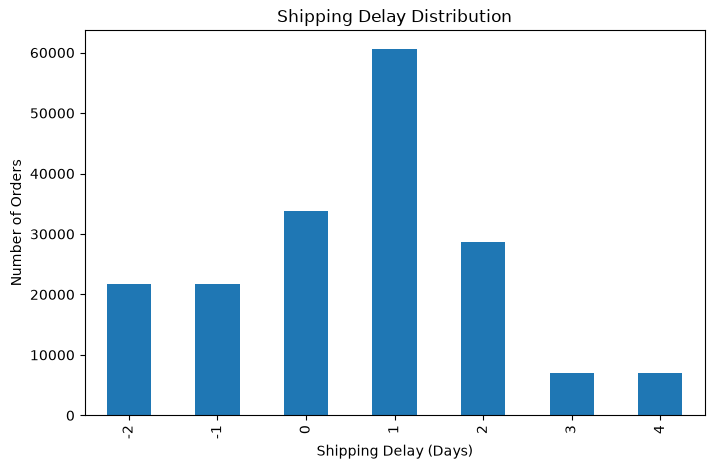

In [26]:
delay_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Shipping Delay Distribution",
    xlabel="Shipping Delay (Days)",
    ylabel="Number of Orders"
)

In [27]:
delivery_by_mode = pd.crosstab(
    df["Shipping Mode"],
    df["Delivery Status"]
)

delivery_by_mode

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping Mode,,,,
First Class,0,26513,1301,0
Same Day,0,4454,444,4839
Second Class,0,26987,1410,6819
Standard Class,41592,41023,4599,20538


In [28]:
import matplotlib.pyplot as plt

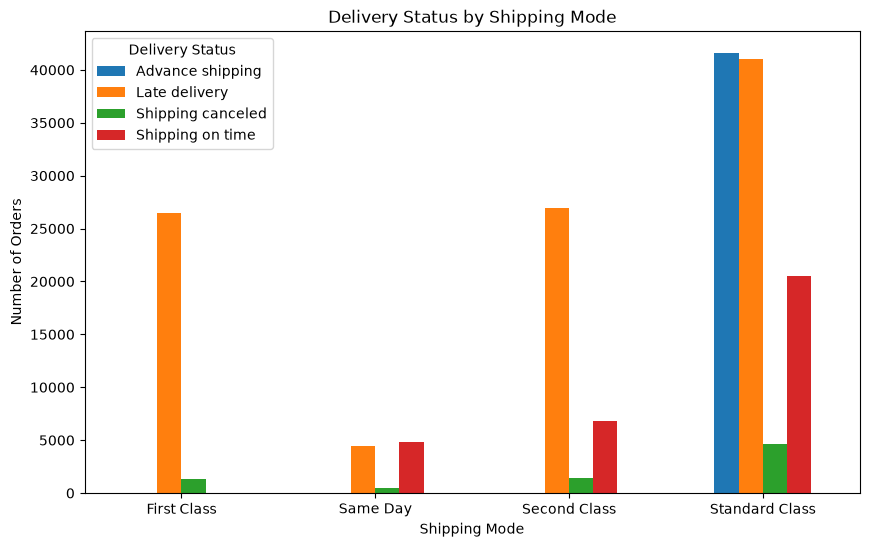

In [29]:
delivery_by_mode.plot(
    kind="bar",
    figsize=(10, 6),
    title="Delivery Status by Shipping Mode",
    xlabel="Shipping Mode",
    ylabel="Number of Orders"
)

plt.xticks(rotation=0)
plt.legend(title="Delivery Status")

In [30]:
df["Order Month"] = df["order date (DateOrders)"].dt.to_period("M")

monthly_late_rate = (
    df.assign(Is_Late=df["Delivery Status"].eq("Late delivery"))
      .groupby("Order Month")["Is_Late"]
      .mean()
      .mul(100)
      .round(2)
)

monthly_late_rate

Order Month
2015-01    54.11
2015-02    54.85
2015-03    54.76
2015-04    53.84
2015-05    55.09
2015-06    54.11
2015-07    55.46
2015-08    55.68
2015-09    56.69
2015-10    54.81
2015-11    54.27
2015-12    54.68
2016-01    55.58
2016-02    54.15
2016-03    55.76
2016-04    55.23
2016-05    55.66
2016-06    56.85
2016-07    51.93
2016-08    55.27
2016-09    54.98
2016-10    54.78
2016-11    54.63
2016-12    56.06
2017-01    53.61
2017-02    54.67
2017-03    55.26
2017-04    53.78
2017-05    53.47
2017-06    53.50
2017-07    54.78
2017-08    56.44
2017-09    54.23
2017-10    53.66
2017-11    55.09
2017-12    55.18
2018-01    56.29
Freq: M, Name: Is_Late, dtype: float64

(array([540, 552, 564, 576]),
 [Text(540, 0, 'Jan\n2015'),
  Text(552, 0, 'Jan\n2016'),
  Text(564, 0, 'Jan\n2017'),
  Text(576, 0, 'Jan\n2018')])

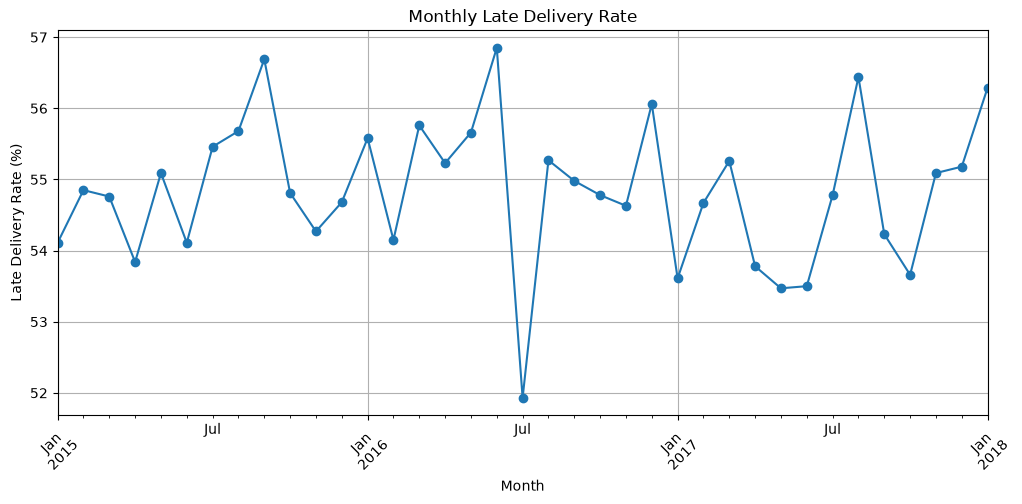

In [31]:
monthly_late_rate.plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    title="Monthly Late Delivery Rate",
    xlabel="Month",
    ylabel="Late Delivery Rate (%)"
)

plt.grid(True)
plt.xticks(rotation=45)

In [32]:
region_analysis = (
    df.assign(Is_Late=df["Delivery Status"].eq("Late delivery"))
      .groupby("Order Region")
      .agg(
          Orders=("Order Id", "count"),
          Late_Rate=("Is_Late", "mean")
      )
)

region_analysis["Late_Rate"] = (
    region_analysis["Late_Rate"] * 100
).round(2)

region_analysis = region_analysis.sort_values(
    "Late_Rate",
    ascending=False
)

region_analysis

,Orders,Late_Rate
Order Region,,
Central Africa,1677,57.96
South Asia,7731,56.27
East Africa,1852,55.94
Western Europe,27109,55.85
South of USA,4045,55.77
Eastern Europe,3920,55.66
East of USA,6915,55.66
Southeast Asia,9539,55.53
Central Asia,553,55.33


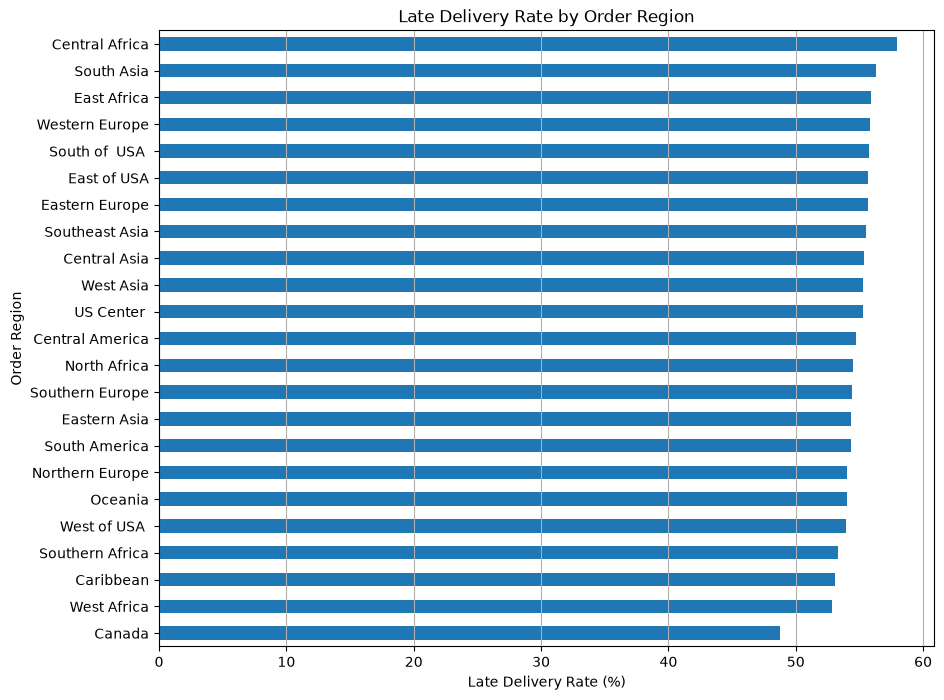

In [33]:
region_analysis["Late_Rate"].sort_values().plot(
    kind="barh",
    figsize=(10, 8),
    title="Late Delivery Rate by Order Region",
    xlabel="Late Delivery Rate (%)",
    ylabel="Order Region"
)

plt.grid(axis="x")

In [34]:
df[[
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Benefit per order"
]].describe()

,Sales,Order Item Total,Order Profit Per Order,Benefit per order
count,180519.000000,180519.000000,180519.000000,180519.000000
mean,203.772096,183.107609,21.974989,21.974989
std,132.273077,120.043670,104.433526,104.433526
min,9.990000,7.490000,-4274.979980,-4274.979980
25%,119.980003,104.379997,7.000000,7.000000
50%,199.919998,163.990005,31.520000,31.520000
75%,299.950012,247.399994,64.800003,64.800003
max,1999.989990,1939.989990,911.799988,911.799988


In [35]:
loss_making = (df["Order Profit Per Order"] < 0).sum()
total_orders = len(df)

loss_percentage = (loss_making / total_orders) * 100

print("Loss-making orders:", loss_making)
print("Total orders:", total_orders)
print("Loss-making percentage:", round(loss_percentage, 2), "%")

Loss-making orders: 33784
Total orders: 180519
Loss-making percentage: 18.71 %


In [36]:
profit_by_delivery = (
    df.groupby("Delivery Status")["Order Profit Per Order"]
      .agg(["mean", "median"])
      .round(2)
)

profit_by_delivery

,mean,median
Delivery Status,,
Advance shipping,22.49,31.67
Late delivery,21.62,31.43
Shipping canceled,20.70,31.57
Shipping on time,22.71,31.74


In [37]:
profit_by_mode = (
    df.groupby("Shipping Mode")["Order Profit Per Order"]
      .agg(["mean", "median"])
      .round(2)
      .sort_values("mean", ascending=False)
)

profit_by_mode

,mean,median
Shipping Mode,,
First Class,23.12,31.69
Standard Class,22.00,31.58
Second Class,21.31,31.50
Same Day,20.85,30.76


In [38]:
profit_by_category = (
    df.groupby("Category Name")["Order Profit Per Order"]
      .mean()
      .round(2)
      .sort_values(ascending=False)
)

profit_by_category


Category Name
Computers               157.59
Garden                   69.10
Crafts                   52.75
Cameras                  51.17
Fishing                  43.65
Children's Clothing      41.68
Sporting Goods           35.07
Music                    33.26
Camping & Hiking         31.14
Consumer Electronics     30.68
Cardio Equipment         30.67
Golf Bags & Carts        29.67
Women's Clothing         29.39
Soccer                   28.27
Women's Golf Clubs       27.78
Basketball               27.55
Health and Beauty        26.23
Golf Shoes               23.68
Kids' Golf Clubs         23.56
Water Sports             20.92
Boxing & MMA             20.43
Baseball & Softball      20.19
Cleats                   20.15
Men's Golf Clubs         19.50
Tennis & Racquet         17.52
Fitness Accessories      17.02
Women's Apparel          16.66
Indoor/Outdoor Games     16.50
Girls' Apparel           14.40
Men's Footwear           14.02
DVDs                     13.78
Hunting & Shooting       

In [39]:
top_10_categories = profit_by_category.head(10)

top_10_categories

Category Name
Computers               157.59
Garden                   69.10
Crafts                   52.75
Cameras                  51.17
Fishing                  43.65
Children's Clothing      41.68
Sporting Goods           35.07
Music                    33.26
Camping & Hiking         31.14
Consumer Electronics     30.68
Name: Order Profit Per Order, dtype: float64

In [40]:
bottom_10_categories = profit_by_category.tail(10).sort_values()

bottom_10_categories



Category Name
CDs                  1.42
Toys                 1.70
Books                2.18
Strength Training    2.99
Video Games          3.24
Golf Balls           5.66
Pet Supplies         7.30
Baby                 7.37
Golf Apparel         7.93
Trade-In             8.13
Name: Order Profit Per Order, dtype: float64

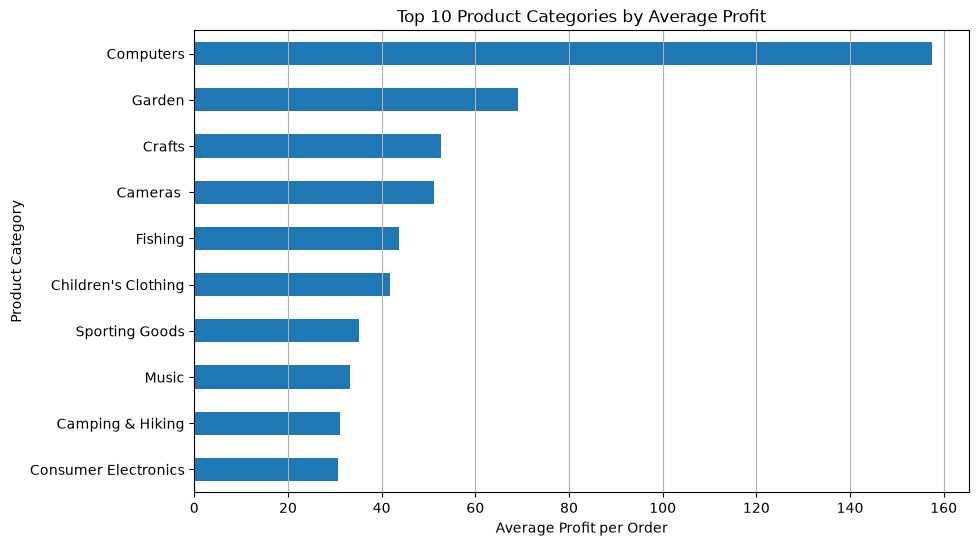

In [41]:
profit_by_category.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Product Categories by Average Profit",
    xlabel="Average Profit per Order",
    ylabel="Product Category"
)

plt.grid(axis="x")

In [42]:
print("Highest average profit category:")
print(profit_by_category.head(5))

print("\nLowest average profit category:")
print(profit_by_category.tail(5).sort_values())



Highest average profit category:
Category Name
Computers    157.59
Garden        69.10
Crafts        52.75
Cameras       51.17
Fishing       43.65
Name: Order Profit Per Order, dtype: float64

Lowest average profit category:
Category Name
CDs                  1.42
Toys                 1.70
Books                2.18
Strength Training    2.99
Video Games          3.24
Name: Order Profit Per Order, dtype: float64


In [43]:
df["Is_Late"] = (
    df["Delivery Status"] == "Late delivery"
).astype(int)

df["Is_Late"].value_counts()



Is_Late
1    98977
0    81542
Name: count, dtype: int64

In [44]:
features = [
    "Days for shipment (scheduled)",
    "Shipping Mode",
    "Market",
    "Order Region",
    "Order Country",
    "Customer Segment",
    "Department Name",
    "Category Name",
    "Order Item Quantity",
    "Order Item Discount Rate",
    "Order Item Product Price"
]

X = df[features]
y = df["Is_Late"]

X.shape, y.shape



((180519, 11), (180519,))

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (144415, 11)
Testing data: (36104, 11)


In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Shipping Mode",
    "Market",
    "Order Region",
    "Order Country",
    "Customer Segment",
    "Department Name",
    "Category Name"
]

numerical_features = [
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Order Item Discount Rate",
    "Order Item Product Price"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (144415, 264)
Processed testing data: (36104, 264)


In [47]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

model.fit(X_train_processed, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

model.fit(X_train_processed, y_train)

print("Model retrained successfully.")

Model retrained successfully.


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (144415, 11)
Testing data: (36104, 11)


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Shipping Mode",
    "Market",
    "Order Region",
    "Order Country",
    "Customer Segment",
    "Department Name",
    "Category Name"
]

numerical_features = [
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Order Item Discount Rate",
    "Order Item Product Price"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (144415, 264)
Processed testing data: (36104, 264)


In [51]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

model.fit(X_train_processed, y_train)

print("Model trained successfully.")

Model trained successfully.


In [52]:
y_pred = model.predict(X_test_processed)

print("Predictions generated successfully.")

Predictions generated successfully.


In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6965
Precision: 0.8442
Recall: 0.5476
F1 Score: 0.6643

Confusion Matrix:
[[14307  2001]
 [ 8956 10840]]


In [54]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test_processed)[:, 1]

auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(auc_score, 4))




ROC-AUC Score: 0.7334


In [55]:
feature_names = preprocessor.get_feature_names_out()

coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Abs_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

top_features = (
    feature_importance
    .sort_values("Abs_Coefficient", ascending=False)
    .head(20)
)

top_features

,Feature,Coefficient,Abs_Coefficient
0,cat__Shipping Mode_First Class,2.155931,2.155931
146,cat__Order Country_Paraguay,-1.227926,1.227926
1,cat__Shipping Mode_Same Day,-1.223213,1.223213
183,cat__Order Country_Turkmenistán,0.934200,0.934200
81,cat__Order Country_Estonia,0.870244,0.870244
3,cat__Shipping Mode_Standard Class,-0.829391,0.829391
193,cat__Order Country_Yibuti,0.736349,0.736349
99,cat__Order Country_Hong Kong,-0.716007,0.716007
141,cat__Order Country_Níger,0.714093,0.714093
82,cat__Order Country_Etiopía,-0.713251,0.713251


In [56]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

tree_model.fit(X_train_processed, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [57]:
tree_pred = tree_model.predict(X_test_processed)

print("Decision Tree predictions generated successfully.")



Decision Tree predictions generated successfully.


In [58]:
print("Accuracy:", round(accuracy_score(y_test, tree_pred), 4))
print("Precision:", round(precision_score(y_test, tree_pred), 4))
print("Recall:", round(recall_score(y_test, tree_pred), 4))
print("F1 Score:", round(f1_score(y_test, tree_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tree_pred))



Accuracy: 0.6971
Precision: 0.8479
Recall: 0.5453
F1 Score: 0.6638

Confusion Matrix:
[[14372  1936]
 [ 9001 10795]]


In [59]:
tree_prob = tree_model.predict_proba(X_test_processed)[:, 1]

tree_auc = roc_auc_score(y_test, tree_prob)

print("Decision Tree ROC-AUC:", round(tree_auc, 4))

Decision Tree ROC-AUC: 0.7312


In [60]:
model_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [0.6965, 0.6971],
    "Precision": [0.8442, 0.8479],
    "Recall": [0.5476, 0.5453],
    "F1 Score": [0.6643, 0.6638],
    "ROC-AUC": [0.7334, 0.7312]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6965,0.8442,0.5476,0.6643,0.7334
1,Decision Tree,0.6971,0.8479,0.5453,0.6638,0.7312


In [61]:
print("KEY OPTIMIZATION FINDINGS")
print("-" * 50)

print("1. Highest late-delivery shipping mode: First Class (95.32%)")
print("2. Largest shipping-mode volume: Standard Class (107,752 orders)")
print("3. Overall late-delivery rate: 54.83%")
print("4. Highest late-delivery region: Central Africa (57.96%)")
print("5. Loss-making records: 18.71%")
print("6. Highest average-profit category: Computers (157.59)")
print("7. Lowest average-profit category: CDs (1.42)")
print("8. Selected predictive model: Logistic Regression")
print("9. Model ROC-AUC: 0.7334")

KEY OPTIMIZATION FINDINGS
--------------------------------------------------
1. Highest late-delivery shipping mode: First Class (95.32%)
2. Largest shipping-mode volume: Standard Class (107,752 orders)
3. Overall late-delivery rate: 54.83%
4. Highest late-delivery region: Central Africa (57.96%)
5. Loss-making records: 18.71%
6. Highest average-profit category: Computers (157.59)
7. Lowest average-profit category: CDs (1.42)
8. Selected predictive model: Logistic Regression
9. Model ROC-AUC: 0.7334


In [62]:
optimization_recommendations = [
    "Prioritize investigation of First Class shipments because they show the highest observed late-delivery rate (95.32%).",
    
    "Use the Logistic Regression model as an early-warning system to identify orders with higher predicted late-delivery risk.",
    
    "Review delivery schedules and planned shipping times, especially for orders predicted to have higher delay risk.",
    
    "Monitor regions with comparatively higher late-delivery rates, particularly Central Africa (57.96%) and South Asia (56.27%).",
    
    "Investigate the 18.71% of records with negative order profit to identify opportunities for reducing operational costs and improving profitability.",
    
    "Give additional business attention to product categories with very low average profit, such as CDs (1.42), while protecting high-performing categories such as Computers (157.59).",
    
    "Continuously monitor late-delivery performance by shipping mode, region, and product category to identify changes in operational performance."
]

for i, recommendation in enumerate(optimization_recommendations, 1):
    print(f"{i}. {recommendation}")

1. Prioritize investigation of First Class shipments because they show the highest observed late-delivery rate (95.32%).
2. Use the Logistic Regression model as an early-warning system to identify orders with higher predicted late-delivery risk.
3. Review delivery schedules and planned shipping times, especially for orders predicted to have higher delay risk.
4. Monitor regions with comparatively higher late-delivery rates, particularly Central Africa (57.96%) and South Asia (56.27%).
5. Investigate the 18.71% of records with negative order profit to identify opportunities for reducing operational costs and improving profitability.
6. Give additional business attention to product categories with very low average profit, such as CDs (1.42), while protecting high-performing categories such as Computers (157.59).
7. Continuously monitor late-delivery performance by shipping mode, region, and product category to identify changes in operational performance.


In [63]:
task4_conclusion = """
The analysis identified significant delivery-performance challenges in the
logistics dataset. Overall, 54.83% of records were classified as late
deliveries. First Class shipments showed the highest observed late-delivery
rate at 95.32%, while Standard Class had the largest order volume with
107,752 records.

The predictive modeling stage compared Logistic Regression and Decision Tree
classifiers. Logistic Regression was selected as the final model because it
achieved a ROC-AUC of 0.7334, recall of 54.76%, precision of 84.42%, and
F1-score of 66.43%. The Decision Tree produced very similar results, with a
ROC-AUC of 0.7312.

The analysis also found that 18.71% of records were loss-making. Product
category profitability varied considerably, with Computers showing the
highest average profit per record at 157.59 and CDs showing the lowest at
1.42.

Overall, the results demonstrate how exploratory analysis and predictive
modeling can support logistics decision-making. The developed approach can
be used as an early-warning framework for identifying potentially
high-risk deliveries and prioritizing operational investigation. Future
work could improve prediction performance by incorporating additional
operational variables, testing advanced machine-learning algorithms, and
optimizing classification thresholds according to business priorities.
"""

print(task4_conclusion)



The analysis identified significant delivery-performance challenges in the
logistics dataset. Overall, 54.83% of records were classified as late
deliveries. First Class shipments showed the highest observed late-delivery
rate at 95.32%, while Standard Class had the largest order volume with
107,752 records.

The predictive modeling stage compared Logistic Regression and Decision Tree
classifiers. Logistic Regression was selected as the final model because it
achieved a ROC-AUC of 0.7334, recall of 54.76%, precision of 84.42%, and
F1-score of 66.43%. The Decision Tree produced very similar results, with a
ROC-AUC of 0.7312.

The analysis also found that 18.71% of records were loss-making. Product
category profitability varied considerably, with Computers showing the
highest average profit per record at 157.59 and CDs showing the lowest at
1.42.

Overall, the results demonstrate how exploratory analysis and predictive
modeling can support logistics decision-making. The developed approac

In [64]:
shipping_analysis = (
    df.groupby("Shipping Mode")
      .agg(
          Orders=("Order Id", "count"),
          Late_Rate=(
              "Delivery Status",
              lambda x: (x == "Late delivery").mean() * 100
          )
      )
      .round(2)
      .sort_values("Late_Rate", ascending=False)
)

shipping_analysis



,Orders,Late_Rate
Shipping Mode,,
First Class,27814,95.32
Second Class,35216,76.63
Same Day,9737,45.74
Standard Class,107752,38.07


In [65]:
monthly_late_rate = (
    df.groupby(df["order date (DateOrders)"].dt.to_period("M"))["Delivery Status"]
      .apply(lambda x: (x == "Late delivery").mean() * 100)
)

monthly_late_rate

order date (DateOrders)
2015-01    54.114994
2015-02    54.853034
2015-03    54.755688
2015-04    53.843153
2015-05    55.086802
2015-06    54.109856
2015-07    55.463295
2015-08    55.679879
2015-09    56.692607
2015-10    54.809506
2015-11    54.269341
2015-12    54.682554
2016-01    55.576453
2016-02    54.147936
2016-03    55.758157
2016-04    55.228566
2016-05    55.658242
2016-06    56.846063
2016-07    51.932139
2016-08    55.268091
2016-09    54.980620
2016-10    54.779548
2016-11    54.625720
2016-12    56.063769
2017-01    53.613188
2017-02    54.667754
2017-03    55.264634
2017-04    53.779739
2017-05    53.470002
2017-06    53.504343
2017-07    54.776232
2017-08    56.437323
2017-09    54.230102
2017-10    53.658537
2017-11    55.085158
2017-12    55.178908
2018-01    56.288271
Freq: M, Name: Delivery Status, dtype: float64

In [66]:
region_analysis = (
    df.groupby("Order Region")
      .agg(
          Orders=("Order Id", "count"),
          Late_Rate=(
              "Delivery Status",
              lambda x: (x == "Late delivery").mean() * 100
          )
      )
      .round(2)
      .sort_values("Late_Rate", ascending=False)
)

region_analysis

,Orders,Late_Rate
Order Region,,
Central Africa,1677,57.96
South Asia,7731,56.27
East Africa,1852,55.94
Western Europe,27109,55.85
South of USA,4045,55.77
Eastern Europe,3920,55.66
East of USA,6915,55.66
Southeast Asia,9539,55.53
Central Asia,553,55.33


In [67]:
profit_by_category = (
    df.groupby("Category Name")["Order Profit Per Order"]
      .mean()
      .sort_values(ascending=False)
)

profit_by_category.head(10)

Category Name
Computers               157.594593
Garden                   69.097128
Crafts                   52.750351
Cameras                  51.165203
Fishing                  43.649106
Children's Clothing      41.684202
Sporting Goods           35.066135
Music                    33.263410
Camping & Hiking         31.135230
Consumer Electronics     30.680742
Name: Order Profit Per Order, dtype: float64

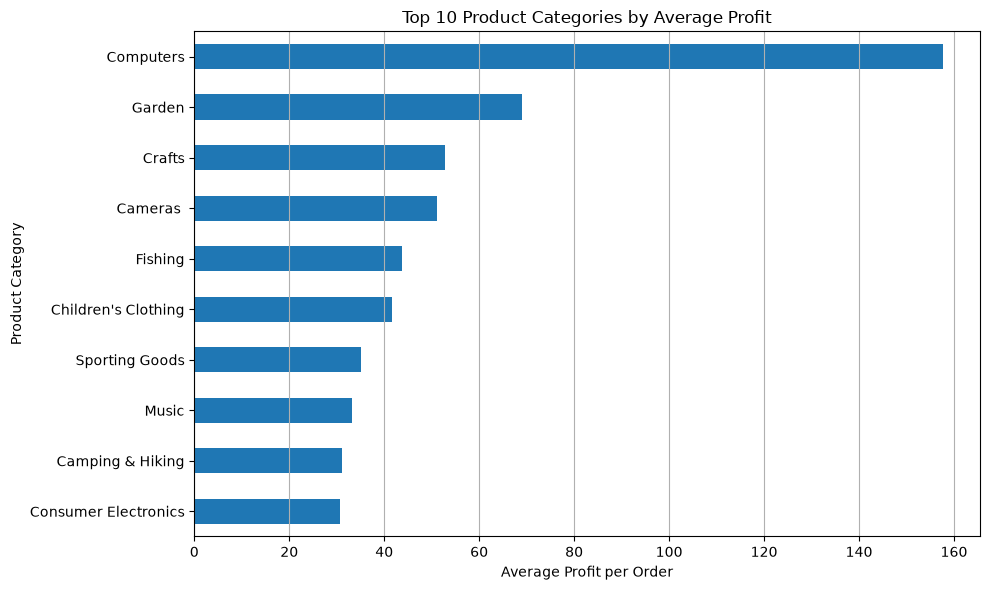

Chart 6 saved successfully.


In [68]:
import matplotlib.pyplot as plt

profit_by_category.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Product Categories by Average Profit",
    xlabel="Average Profit per Order",
    ylabel="Product Category"
)

plt.grid(axis="x")
plt.tight_layout()

plt.savefig(
    "../image/charts/06_top_10_categories_by_average_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 6 saved successfully.")